# Customer Telecommunications Churn Prediction

## Project Overview

Customer churn occurs when a customer stops using a company's
products or services.

The goal of this project is to develop a machine learning model
that predicts whether a telecommunications customer is likely
to leave the company.

## Machine Learning Task

- **Learning Type:** Supervised Learning
- **Problem Type:** Binary Classification
- **Target Variable:** Churn
- **Positive Class:** Yes (1)
- **Negative Class:** No (0)

## Project Objectives

1. Explore and understand the customer dataset.
2. Clean and prepare the data.
3. Identify patterns associated with customer churn.
4. Train classification models.
5. Evaluate and compare model performance.
6. Improve the selected model.
7. Make predictions for new customers.

## 1. Data Loading

### 1.1 Import Required Libraries

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


In [2]:
df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

### 1.3 Dataset Inspection

In [3]:
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
print("\nColumn names:")
print(df.columns.tolist())


Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [5]:
print("\nDataset information:")
df.info()


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null

In [6]:
print("\nStatistical summary:")
df.describe(include="all")


Statistical summary:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,20.2,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,...,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


### 1.4 Target Variable Inspection

We examine the distribution of the target variable, Churn,
to understand how many customers stayed and how many left.

In [7]:
df["Churn"].value_counts

<bound method IndexOpsMixin.value_counts of 0        No
1        No
2       Yes
3        No
4       Yes
       ... 
7038     No
7039     No
7040     No
7041    Yes
7042     No
Name: Churn, Length: 7043, dtype: str>

In [8]:
# Calculate churn percentages
df["Churn"].value_counts(normalize=True).mul(100).round(2)

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

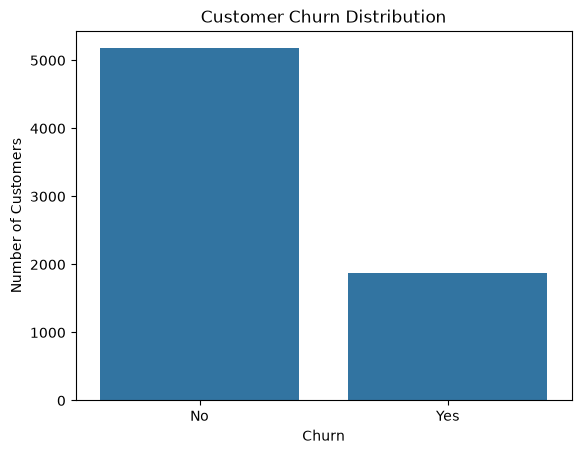

In [9]:
sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

In [10]:
churn_summery = pd.DataFrame(
    {
        "count": df["Churn"].value_counts(),
        "percentage": df["Churn"].value_counts(normalize=True).mul(100).round(2),
    }
)

churn_summery

,count,percentage
Churn,,
No,5174,73.46
Yes,1869,26.54


## 2. Data Cleaning and Preparation

### 2.1 Check for Duplicate Records

Duplicate records can affect statistical analysis and model training.
We first identify whether our dataset contains duplicate rows.

In [11]:
int(df.duplicated().sum())

0

In [12]:
# Count missing values in each column
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [13]:
(df.isnull().mean() * 100).round(2)

customerID          0.0
gender              0.0
SeniorCitizen       0.0
Partner             0.0
Dependents          0.0
tenure              0.0
PhoneService        0.0
MultipleLines       0.0
InternetService     0.0
OnlineSecurity      0.0
OnlineBackup        0.0
DeviceProtection    0.0
TechSupport         0.0
StreamingTV         0.0
StreamingMovies     0.0
Contract            0.0
PaperlessBilling    0.0
PaymentMethod       0.0
MonthlyCharges      0.0
TotalCharges        0.0
Churn               0.0
dtype: float64

In [14]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

### 2.2 Investigate TotalCharges

We inspect TotalCharges because it is currently stored as a string
instead of a numerical column.

In [15]:
# Inspect the TotalCharges column
df["TotalCharges"].head(20)

0       29.85
1      1889.5
2      108.15
3     1840.75
4      151.65
5       820.5
6      1949.4
7       301.9
8     3046.05
9     3487.95
10     587.45
11      326.8
12     5681.1
13     5036.3
14    2686.05
15    7895.15
16    1022.95
17    7382.25
18     528.35
19     1862.9
Name: TotalCharges, dtype: str

In [16]:
# Check for empty or whitespace-only values
int((df["TotalCharges"].str.strip() == "").sum())

11

In [17]:
# to change TotalCharges to numeric value
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

In [18]:
df["TotalCharges"].dtype

dtype('float64')

In [19]:
int(df["TotalCharges"].isnull().sum())

11

In [20]:
df.loc[
    df["TotalCharges"].isna(),
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"],
]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [21]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [22]:
print("Missing TotalCharges:", df["TotalCharges"].isna().sum())
print("TotalCharges data type:", df["TotalCharges"].dtype)

print("\nCustomers with zero tenure:")
display(
    df.loc[df["tenure"] == 0, ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]]
)

Missing TotalCharges: 0
TotalCharges data type: float64

Customers with zero tenure:


,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,0.0,No
753,0,20.25,0.0,No
936,0,80.85,0.0,No
1082,0,25.75,0.0,No
1340,0,56.05,0.0,No
3331,0,19.85,0.0,No
3826,0,25.35,0.0,No
4380,0,20.00,0.0,No
5218,0,19.70,0.0,No
6670,0,73.35,0.0,No


## Phase 3: Exploratory Data Analysis (EDA)

### Step 3.1: Target Variable Distribution

Analyze the distribution of the target variable (`Churn`) to understand the proportion of customers who leave the company compared with those who remain.

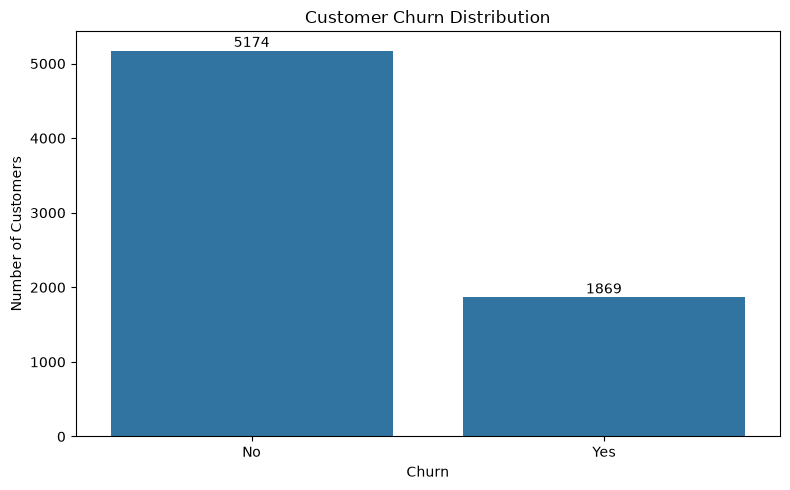

In [23]:
churn_counts = df["Churn"].value_counts()

plt.figure(figsize=(8, 5))

sns.barplot(x=churn_counts.index, y=churn_counts.values)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

for index, value in enumerate(churn_counts.values):
    plt.text(index, value + 50, str(value), ha="center")

plt.tight_layout()
plt.show()

In [24]:
churn_percentages = df["Churn"].value_counts(normalize=True).mul(100).round(2)

display(churn_percentages)

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

### Step 3.2: Customer Tenure and Churn

Analyze the relationship between customer tenure and churn.

The objective is to understand whether customers who have stayed with the company for shorter or longer periods are more likely to leave.

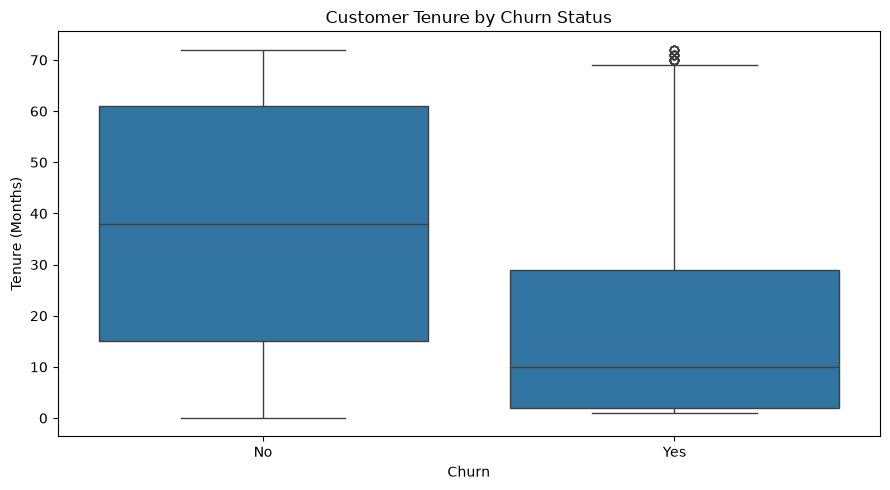

In [25]:
plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x="Churn", y="tenure")

plt.title("Customer Tenure by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.tight_layout()
plt.show()

In [26]:
tenure_summary = (
    df.groupby("Churn")["tenure"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

display(tenure_summary)

,count,mean,median,min,max
Churn,,,,,
No,5174,37.57,38.0,0,72
Yes,1869,17.98,10.0,1,72


### Step 3.3: Monthly Charges and Churn

Analyze the relationship between customers' monthly charges and their churn status.

The objective is to understand whether customers who pay higher monthly charges are more likely to leave the company.

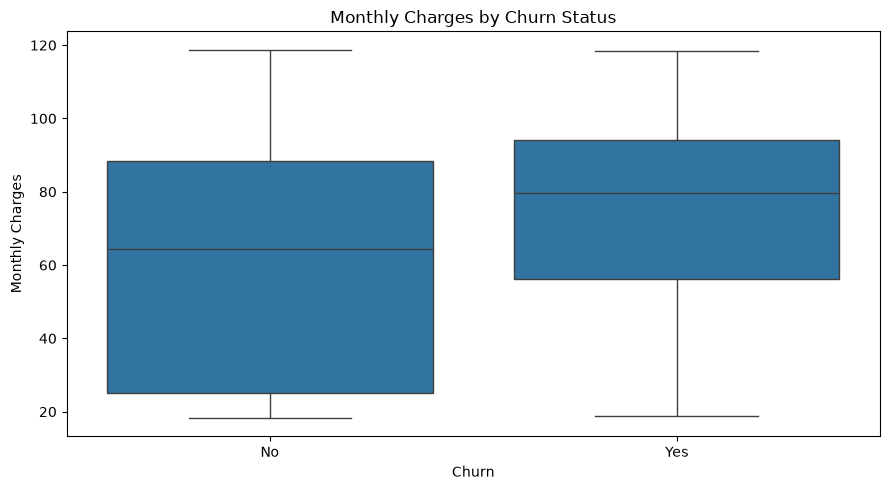

In [27]:
plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x="Churn", y="MonthlyCharges")

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.tight_layout()
plt.show()

In [28]:
monthly_charges_summary = (
    df.groupby("Churn")["MonthlyCharges"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

display(monthly_charges_summary)

,count,mean,median,min,max
Churn,,,,,
No,5174,61.27,64.43,18.25,118.75
Yes,1869,74.44,79.65,18.85,118.35


### Step 3.4: Contract Type and Churn

Analyze the relationship between contract types and customer churn.

The objective is to determine whether customers with different contract arrangements have different churn rates.

In [29]:
contract_churn = (
    df.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
    .round(2)
)

display(contract_churn)

Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64

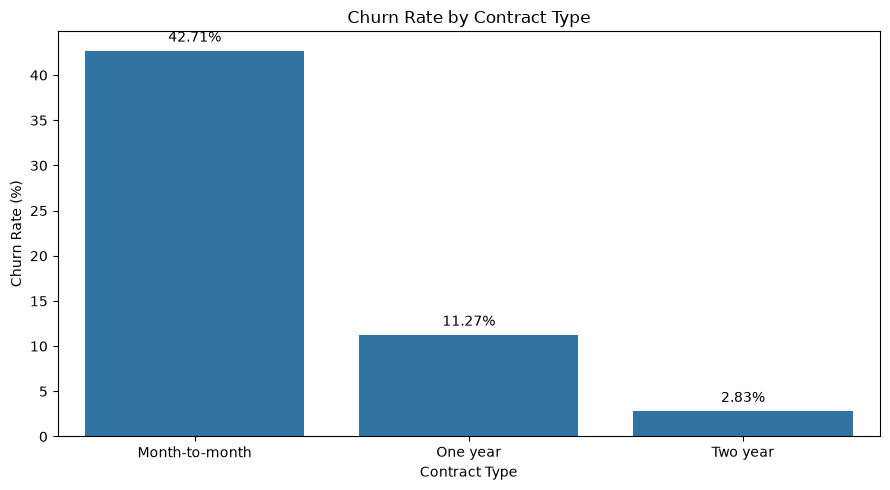

In [30]:
plt.figure(figsize=(9, 5))

sns.barplot(x=contract_churn.index, y=contract_churn.values)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")

for index, value in enumerate(contract_churn.values):
    plt.text(index, value + 1, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

#### Key Findings

- Month-to-month contracts have a churn rate of 42.71%.
- One-year contracts have a churn rate of 11.27%.
- Two-year contracts have a churn rate of 2.83%.
- Customers with month-to-month contracts are considerably more likely to churn than customers with longer-term contracts.

**Conclusion:** Contract type appears to be an important feature associated with customer churn.

### Phase 4: Feature Engineering and Data Preparation

#### Step 4.1: Separate Features and Target

Separate the independent variables (features) from the dependent variable (target).

- X contains the customer information used for prediction.
- y contains the target variable (Churn).

The customerID column will be excluded because it is an identifier rather than a meaningful customer characteristic.

In [31]:
# Separate features and target

X = df.drop(columns=["customerID", "Churn"])

y = df["Churn"].map({"No": 0, "Yes": 1})

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget values:")
print(y.value_counts())

Features shape: (7043, 19)
Target shape: (7043,)

Target values:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [32]:
print("Feature columns:")
print(X.columns.tolist())

print("\nTarget classes:")
print(y.unique())

print("\nMissing values in features:", X.isnull().sum().sum())
print("Missing values in target:", y.isnull().sum())

Feature columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']

Target classes:
[0 1]

Missing values in features: 0
Missing values in target: 0


#### Step 4.2: Train-Test Split

Split the dataset into training and testing sets.

- Training set: 80% of the dataset.
- Testing set: 20% of the dataset.

Stratification is used to preserve the original class distribution of the target variable in both sets.

In [33]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (5634, 19)
Testing features: (1409, 19)

Training target: (5634,)
Testing target: (1409,)


In [34]:
print("Training target distribution:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

Training target distribution:
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64

Testing target distribution:
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64


In [35]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (5634, 19)
Testing features: (1409, 19)

Training target: (5634,)
Testing target: (1409,)


#### Step 4.3: Feature Encoding and Scaling

Machine learning algorithms generally require numerical input.

We will:
- Apply One-Hot Encoding to categorical features.
- Apply StandardScaler to numerical features.
- Use ColumnTransformer to combine both preprocessing operations.

The preprocessing transformations will be fitted using training data only to prevent data leakage.

In [36]:
numeric_features = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["str", "object", "category"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

print("\nNumber of numerical features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Number of numerical features: 4
Number of categorical features: 15


In [37]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ]
)

In [38]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Processed training data:", X_train_processed.shape)
print("Processed testing data:", X_test_processed.shape)

Processed training data: (5634, 45)
Processed testing data: (1409, 45)


In [39]:
print("Training data type:", type(X_train_processed))
print("Testing data type:", type(X_test_processed))

print("\nTraining samples:", X_train_processed.shape[0])
print("Testing samples:", X_test_processed.shape[0])

print("\nNumber of processed features:", X_train_processed.shape[1])

Training data type: <class 'numpy.ndarray'>
Testing data type: <class 'numpy.ndarray'>

Training samples: 5634
Testing samples: 1409

Number of processed features: 45


# Phase 5: Model Training

## Step 5.1: Logistic Regression

Train a Logistic Regression classifier to predict customer churn.

Logistic Regression is a supervised machine learning classification algorithm that estimates the probability of a customer belonging to a particular class.

The model will use the preprocessed training dataset to learn patterns associated with customer churn.

In [40]:
from sklearn.linear_model import LogisticRegression

# Initialize the model
logistic_model = LogisticRegression(max_iter=1000, random_state=42)

# Train the model
logistic_model.fit(X_train_processed, y_train)

print("Logistic Regression training completed successfully!")

Logistic Regression training completed successfully!


In [41]:
print("Model:", logistic_model)
print("Number of features learned:", logistic_model.n_features_in_)
print("Number of classes:", logistic_model.classes_)

Model: LogisticRegression(max_iter=1000, random_state=42)
Number of features learned: 45
Number of classes: [0 1]


### Step 5.2: Making Predictions

Use the trained Logistic Regression model to predict customer churn
for the testing dataset.

The testing dataset was not used during model training.

In [42]:
y_pred = logistic_model.predict(X_test_processed)

print("First 20 actual values:")
print(y_test.head(20).values)

print("\nFirst 20 predicted values:")
print(y_pred[:20])

First 20 actual values:
[0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 0 0 0 0]

First 20 predicted values:
[0 1 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 1 0 0]


In [43]:
comparison = pd.DataFrame({"Actual": y_test.values, "Predicted": y_pred})

display(comparison.head(20))

,Actual,Predicted
0,0,0
1,0,1
2,0,0
3,0,0
4,0,0
5,0,1
6,0,0
7,0,0
8,0,0
9,1,0


### Step 5.3: Evaluating the Logistic Regression Model

Evaluate the model using accuracy, precision, recall, and F1-score.

These metrics help us understand how well the model identifies
customers who are likely to churn.

In [44]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("Precision:", precision_score(y_test, y_pred))

print("Recall:", recall_score(y_test, y_pred))

print("F1-score:", f1_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["No Churn", "Churn"]))

Accuracy: 0.8055358410220014
Precision: 0.6572327044025157
Recall: 0.5588235294117647
F1-score: 0.6040462427745664

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



### Step 5.4: Confusion Matrix

A confusion matrix helps us understand the number of correct
and incorrect predictions made by our classification model.

It shows:
- True Negatives (TN)
- False Positives (FP)
- False Negatives (FN)
- True Positives (TP)

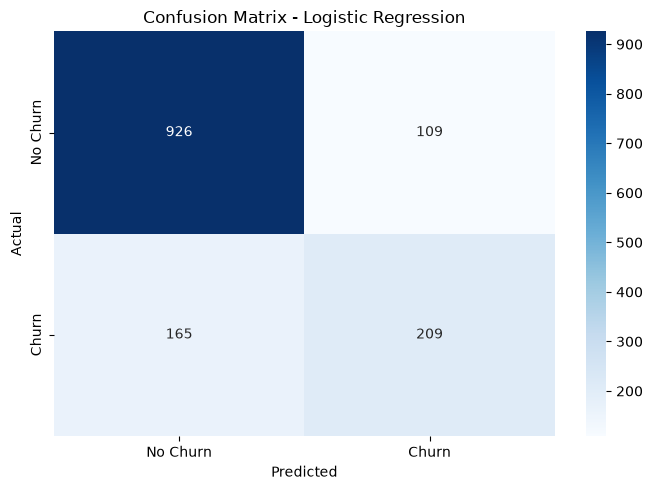

In [45]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"],
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()


165+209=374


There were 374 customers who actually churned.

Out of these:
- 209 were correctly identified.
- 165 were missed.
Therefore:

Recall= 209/374 * 100

Recall= 55.88%


This confirms our earlier recall result.

Now examine the customers who stayed:

926+109=1035


The model correctly identified 926 of them.

Specificity=926\1035 * 100

Specificity = 89.47%


This shows that the model is considerably better at identifying customers who stay than customers who leave.

### Step 6.1: Logistic Regression with Balanced Class Weights

Train a second Logistic Regression model using balanced class weights.

The balanced option assigns weights inversely proportional
to class frequencies to help address class imbalance.

We will compare its performance with our original model.

In [ ]:
balanced_logistic_model = LogisticRegression(
    max_iter=1000, random_state=42, class_weight="balanced"
)

balanced_logistic_model.fit(X_train_processed, y_train)

print("Balanced Logistic Regression training completed!")

Balanced Logistic Regression training completed!


In [ ]:
y_pred_balanced = balanced_logistic_model.predict(X_test_processed)

print("First 20 balanced predictions:")
print(y_pred_balanced[:20])

First 20 balanced predictions:
[0 1 0 1 0 1 1 0 0 1 1 0 0 1 0 0 0 1 0 0]


In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred_balanced))

print("Precision:", precision_score(y_test, y_pred_balanced))

print("Recall:", recall_score(y_test, y_pred_balanced))

print("F1-score:", f1_score(y_test, y_pred_balanced))

print("\nClassification Report:")

print(
    classification_report(y_test, y_pred_balanced, target_names=["No Churn", "Churn"])
)

Accuracy: 0.7381121362668559
Precision: 0.504302925989673
Recall: 0.7834224598930482
F1-score: 0.6136125654450262

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



### Step 6.2: Confusion Matrix - Balanced Logistic Regression

Visualize the confusion matrix of the balanced Logistic Regression model.

Compare its predictions with the original Logistic Regression model
to understand how balanced class weights affect classification.

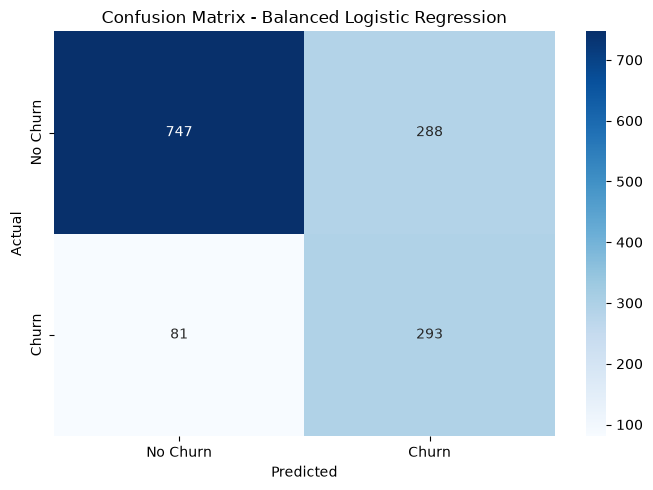

In [ ]:
cm_balanced = confusion_matrix(y_test, y_pred_balanced)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_balanced,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"],
)

plt.title("Confusion Matrix - Balanced Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

### Step 6.3: Comparing Logistic Regression Models

Compare the original Logistic Regression model with the
balanced Logistic Regression model.

Evaluate their accuracy, precision, recall, and F1-score
to understand the effect of class weighting.

In [ ]:
model_comparison = pd.DataFrame(
    {
        "Model": ["Original Logistic Regression", "Balanced Logistic Regression"],
        "Accuracy": [
            accuracy_score(y_test, y_pred),
            accuracy_score(y_test, y_pred_balanced),
        ],
        "Precision": [
            precision_score(y_test, y_pred),
            precision_score(y_test, y_pred_balanced),
        ],
        "Recall": [recall_score(y_test, y_pred), recall_score(y_test, y_pred_balanced)],
        "F1-score": [f1_score(y_test, y_pred), f1_score(y_test, y_pred_balanced)],
    }
)

display(model_comparison.round(4))

,Model,Accuracy,Precision,Recall,F1-score
0,Original Logistic Regression,0.8055,0.6572,0.5588,0.6040
1,Balanced Logistic Regression,0.7381,0.5043,0.7834,0.6136


### Step 7.1: Training a Decision Tree Classifier

Train a Decision Tree Classifier using the processed training dataset.

The model will learn patterns and decision rules that help
predict whether a customer will churn.

In [ ]:
from sklearn.tree import DecisionTreeClassifier

decision_tree_model = DecisionTreeClassifier(random_state=42)

decision_tree_model.fit(X_train_processed, y_train)

print("Decision Tree training completed!")

Decision Tree training completed!


In [ ]:
print("Model:", decision_tree_model)

print("Number of features learned:", decision_tree_model.n_features_in_)

print("Number of classes:", decision_tree_model.classes_)

print("Tree depth:", decision_tree_model.get_depth())

print("Number of leaves:", decision_tree_model.get_n_leaves())

Model: DecisionTreeClassifier(random_state=42)
Number of features learned: 45
Number of classes: [0 1]
Tree depth: 23
Number of leaves: 1102


### Step 7.2: Making Predictions with Decision Tree

Use the trained Decision Tree model to predict customer churn
for the testing dataset.

Compare the predicted values with the actual customer outcomes.

In [ ]:
y_pred_tree = decision_tree_model.predict(X_test_processed)

print("First 20 actual values:")
print(y_test.head(20).values)

print("\nFirst 20 predicted values:")
print(y_pred_tree[:20])

First 20 actual values:
[0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 0 0 0 0]

First 20 predicted values:
[0 1 0 1 0 0 0 0 0 1 0 0 1 1 0 0 0 0 1 0]


In [ ]:
tree_comparison = pd.DataFrame({"Actual": y_test.values, "Predicted": y_pred_tree})

display(tree_comparison.head(20))

,Actual,Predicted
0,0,0
1,0,1
2,0,0
3,0,1
4,0,0
5,0,0
6,0,0
7,0,0
8,0,0
9,1,1


In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred_tree))

print("Precision:", precision_score(y_test, y_pred_tree))

print("Recall:", recall_score(y_test, y_pred_tree))

print("F1-score:", f1_score(y_test, y_pred_tree))

print("\nClassification Report:")

print(classification_report(y_test, y_pred_tree, target_names=["No Churn", "Churn"]))

Accuracy: 0.7210787792760823
Precision: 0.4754521963824289
Recall: 0.4919786096256685
F1-score: 0.4835742444152431

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.81      0.80      0.81      1035
       Churn       0.48      0.49      0.48       374

    accuracy                           0.72      1409
   macro avg       0.64      0.65      0.65      1409
weighted avg       0.72      0.72      0.72      1409



### Step 7.3: Confusion Matrix - Decision Tree

Visualize the confusion matrix of the Decision Tree model.

Identify the number of:
- True Negatives
- False Positives
- False Negatives
- True Positives

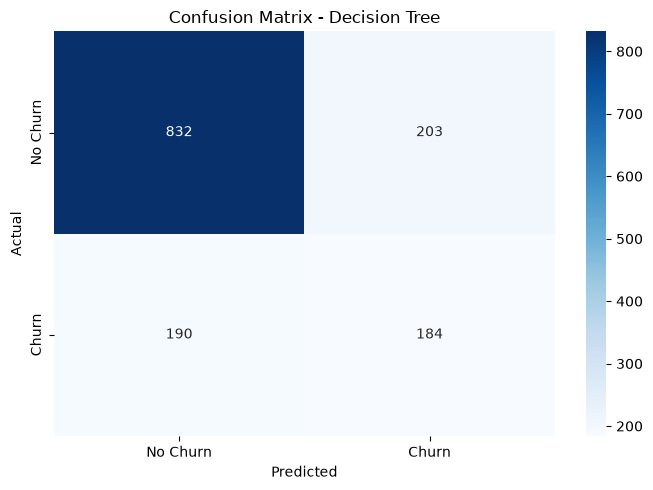

In [ ]:
cm_tree = confusion_matrix(y_test, y_pred_tree)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_tree,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"],
)

plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

## Phase 8: Final Model and Pipeline

### Step 8.1: Building the Final Machine Learning Pipeline

Combine the data preprocessing steps and the selected
Balanced Logistic Regression model into a single pipeline.

This ensures that new customer data receives the same
preprocessing before predictions are generated.

In [ ]:
from sklearn.pipeline import Pipeline

final_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced"),
        ),
    ]
)

final_model.fit(X_train, y_train)

print("Final machine learning pipeline trained successfully!")

Final machine learning pipeline trained successfully!


In [58]:
print("Pipeline:")
print(final_model)

print("\nPipeline steps:")
print(final_model.named_steps.keys())

print("\nNumber of features:")
print(final_model.n_features_in_)

print("\nClasses:")
print(final_model.classes_)

Pipeline:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                     

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
)

# Generate predictions
y_pred_final = final_model.predict(X_test)

# Calculate evaluation metrics
print("Final Pipeline Evaluation")
print("-------------------------")

print("Accuracy:", accuracy_score(y_test, y_pred_final))
print("Precision:", precision_score(y_test, y_pred_final))
print("Recall:", recall_score(y_test, y_pred_final))
print("F1 Score:", f1_score(y_test, y_pred_final))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_final))

Final Pipeline Evaluation
-------------------------
Accuracy: 0.7381121362668559
Precision: 0.504302925989673
Recall: 0.7834224598930482
F1 Score: 0.6136125654450262

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



In [ ]:
from pathlib import Path

import joblib

# Create artifacts directory
artifacts_dir = Path("../artifacts")
artifacts_dir.mkdir(parents=True, exist_ok=True)

# Define model path
model_path = artifacts_dir / "customer_churn_pipeline.joblib"

# Save the trained pipeline
joblib.dump(final_model, model_path)

print(f"Model saved successfully: {model_path}")

Model saved successfully: ../artifacts/customer_churn_pipeline.joblib
